 ## Train a deep neural network on the Alzheimer4 MRI slices dataset.  

### Setup

In [3]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   ## hide TensorFlow's CPU/CUDA info messages

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image

import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Conv2D, Flatten, Dense, Dropout, BatchNormalization, MaxPooling2D

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

I0000 00:00:1792633657.097375   20054 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792633658.221627   20054 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [5]:
## Dataset location (extracted from AlzheimerDataset4.zip into this folder)
DATA_DIR = "data/AlzheimerDataset4/Alzheimer_s Dataset"

## Class folders, in label order:
## 0 --> Non Demented, 1 --> Very Mild Dementia, 2 --> Mild Dementia, 3 --> Moderate Dementia
CLASSES = ["NonDemented", "VeryMildDemented", "MildDemented", "ModerateDemented"]

IMG_SIZE = (128, 128)

In [6]:
def load_split(split):
    """Load every image in DATA_DIR/<split>/<class>/, resized to IMG_SIZE.

    Returns
      data   : (N, 128, 128) array of grayscale pixel values (0-255)
      labels : (N,) array of integer class labels 0-3
      paths  : list of the N file paths, in the same order
    """
    data, labels, paths = [], [], []
    for label, cls in enumerate(CLASSES):
        folder = os.path.join(DATA_DIR, split, cls)
        for filename in sorted(os.listdir(folder)):
            path = os.path.join(folder, filename)
            img = np.array(Image.open(path).resize(IMG_SIZE))
            if img.shape == IMG_SIZE:          ## skip any non-grayscale images
                data.append(img)
                labels.append(label)
                paths.append(path)
    return np.array(data), np.array(labels), paths

### Import training Dataset

In [7]:
train_data, train_y, train_paths = load_split("train")

## One-hot labels (same as the original OneHotEncoder output, shape (N, 4))
train_label = np.eye(len(CLASSES))[train_y]

print("train_data :", train_data.shape)
print("train_label:", train_label.shape)
print(pd.Series(train_y).map(dict(enumerate(CLASSES))).value_counts())

train_data : (5121, 128, 128)
train_label: (5121, 4)
NonDemented         2560
VeryMildDemented    1792
MildDemented         717
ModerateDemented      52
Name: count, dtype: int64


### Question 1. Import test Dataset

In [8]:
test_data, test_y, test_paths = load_split("test")
test_label = np.eye(len(CLASSES))[test_y]

print("test_data :", test_data.shape)
print("test_label:", test_label.shape)
print(pd.Series(test_y).map(dict(enumerate(CLASSES))).value_counts())

test_data : (1279, 128, 128)
test_label: (1279, 4)
NonDemented         640
VeryMildDemented    448
MildDemented        179
ModerateDemented     12
Name: count, dtype: int64


### Show one image

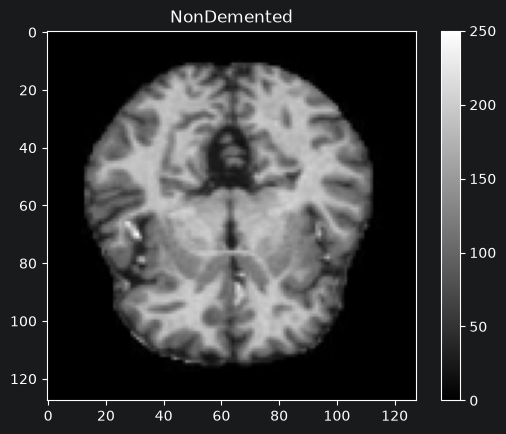

In [9]:
## If you inspect the first image in the training set,
## you will see that the pixel values fall in the range of 0 to 255:
plt.figure()
plt.imshow(train_data[1], cmap="gray")
plt.colorbar()
plt.grid(False)
plt.title(CLASSES[train_y[1]])
plt.show()

###  Question 2.

1. Perform LDA, QDA, Logistic Regression and Categorical Linear Regression on the dataset. 
 
2. For each model, find the confusion Matrix of training and testing

In [10]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
import time

## Flatten each 128x128 image into a 16384-long row and scale pixels to [0, 1].
## float32 halves the memory (5121 x 16384 is ~335 MB instead of ~670 MB).
X_train = (train_data.reshape(len(train_data), -1) / 255).astype(np.float32)
X_test  = (test_data.reshape(len(test_data), -1) / 255).astype(np.float32)

print("X_train:", X_train.shape, "  X_test:", X_test.shape)

X_train: (5121, 16384)   X_test: (1279, 16384)


In [11]:
## Categorical linear regression: regress on the one-hot labels and predict the
## class whose column gets the largest fitted value. Wrapped in a class so it has
## the same fit/predict interface as the sklearn classifiers.
class LinRegClassifier:
    def fit(self, X, y):
        self.lr = LinearRegression().fit(X, np.eye(len(CLASSES))[y])
        return self

    def predict(self, X):
        return np.argmax(self.lr.predict(X), axis=1)

Notes on the models:
- With 16384 pixels and only 5121 training images there are more features than samples, so linear regression has an exact
  (minimum-norm) fit to the training data.
- QDA needs a separate covariance matrix for each class, and each class has fewer images than pixels, so those matrices can't be
  estimated (scikit-learn raises an error). So we first project the images onto their top 40 principal components (PCA fitted on
  the training set only) and run QDA there. We use 40 because the smallest class, ModerateDemented, has just 52 training images, and
  each class needs more samples than dimensions. `reg_param` adds a little extra stabilization.
- Logistic regression can take a few minutes, and may print a convergence warning at `max_iter`.

In [12]:
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

models = {
    "LDA": LinearDiscriminantAnalysis(),
    "QDA (on 40 PCA components)": make_pipeline(PCA(n_components=40, random_state=0),
                                                QuadraticDiscriminantAnalysis(reg_param=0.1)),
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Categorical Linear Regression": LinRegClassifier(),
}

In [13]:
preds = {}   ## predictions for each model: (train, test)

In [14]:
## Models already in preds are skipped, so if a later model fails can just be rerun
for name, m in models.items():
    if name in preds:
        continue
    t0 = time.time()
    m.fit(X_train, train_y)
    preds[name] = (m.predict(X_train), m.predict(X_test))
    print("%-30s fit + predict: %.1f s" % (name, time.time() - t0))

LDA                            fit + predict: 48.7 s
QDA (on 40 PCA components)     fit + predict: 3.1 s
Logistic Regression            fit + predict: 83.3 s
Categorical Linear Regression  fit + predict: 28.7 s


In [15]:
## Accuracy summary. Balanced accuracy = mean recall over the 4 classes, which matters here
## because the classes are very unbalanced (a model that always says "NonDemented" gets 50% accuracy).
results = pd.DataFrame({
    "train acc":          [accuracy_score(train_y, p[0]) for p in preds.values()],
    "test acc":           [accuracy_score(test_y, p[1]) for p in preds.values()],
    "train balanced acc": [balanced_accuracy_score(train_y, p[0]) for p in preds.values()],
    "test balanced acc":  [balanced_accuracy_score(test_y, p[1]) for p in preds.values()],
}, index=preds.keys())

results.round(3)

,train acc,test acc,train balanced acc,test balanced acc
LDA,1.000,0.396,1.000,0.290
QDA (on 40 PCA components),0.793,0.535,0.851,0.369
Logistic Regression,1.000,0.598,1.000,0.365
Categorical Linear Regression,1.000,0.561,1.000,0.449


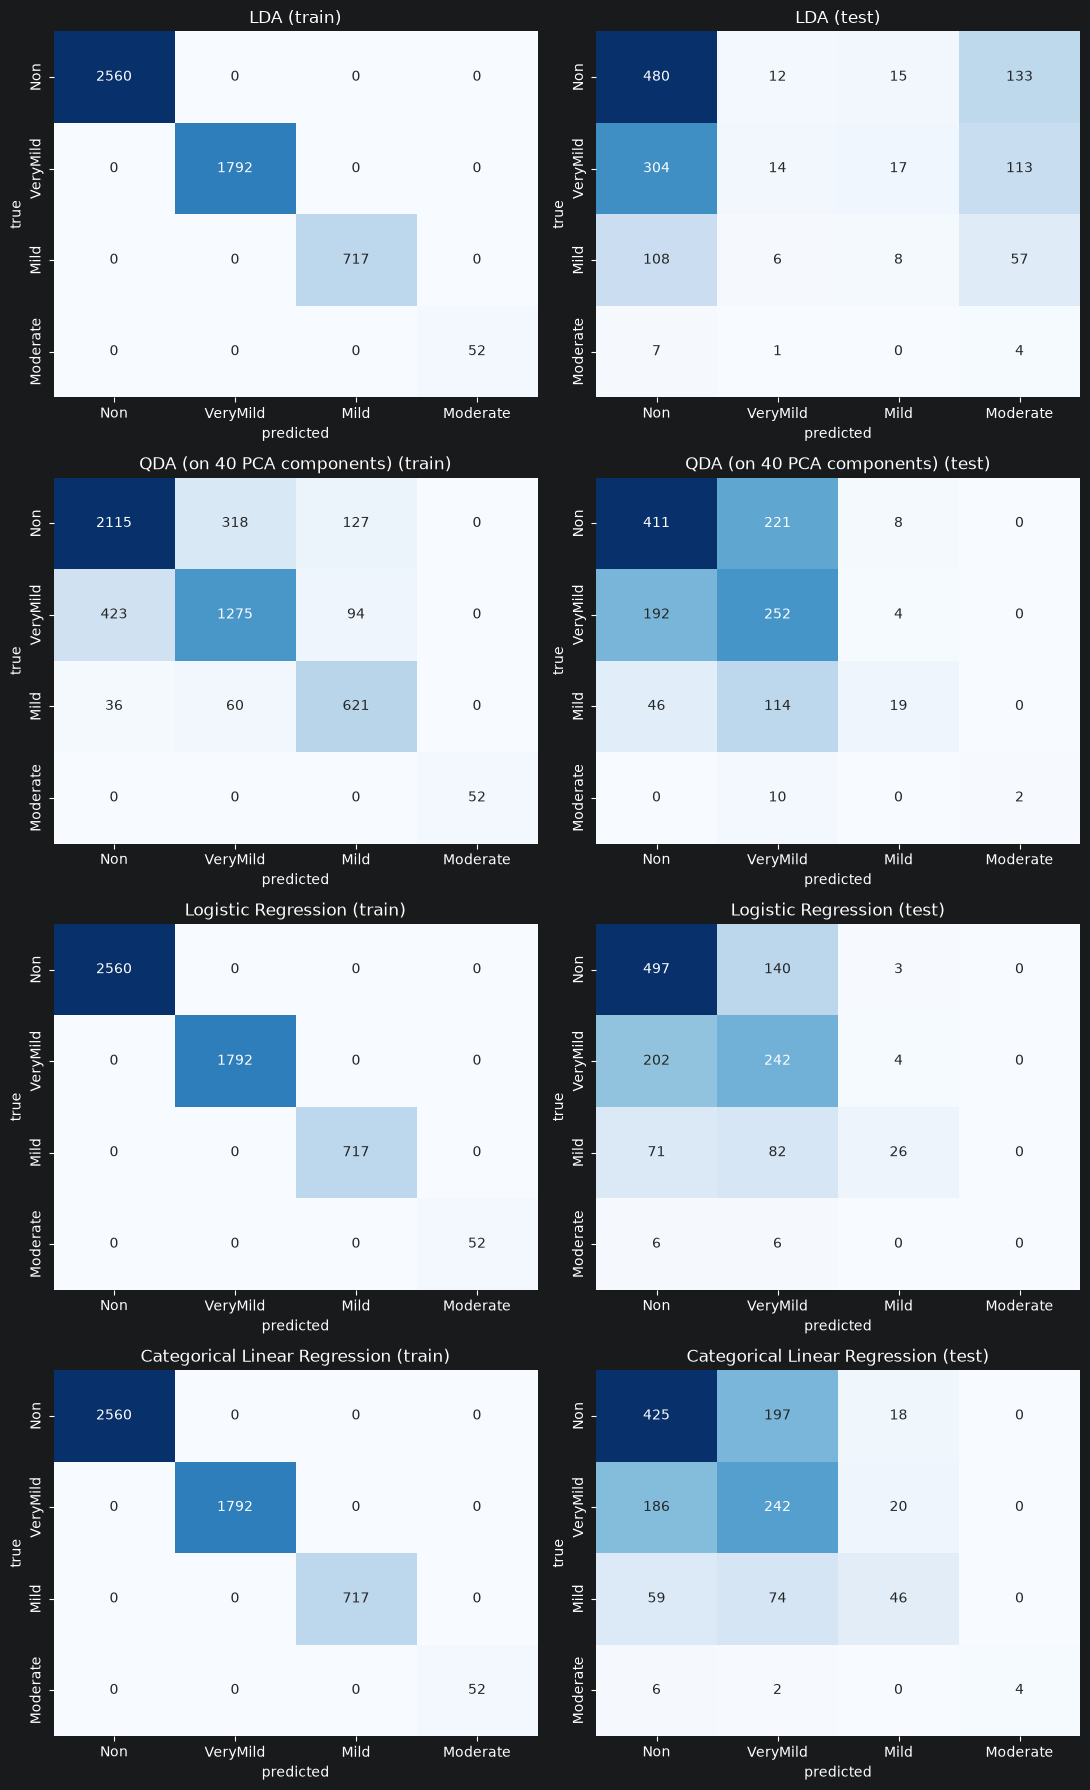

In [16]:
## Confusion matrices: rows = true class, columns = predicted class
short = ["Non", "VeryMild", "Mild", "Moderate"]

f, axes = plt.subplots(len(models), 2, figsize=(11, 18))
for row, (name, (p_train, p_test)) in enumerate(preds.items()):
    for col, (y_true, y_pred, split) in enumerate([(train_y, p_train, "train"), (test_y, p_test, "test")]):
        cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=short, yticklabels=short, ax=axes[row, col])
        axes[row, col].set_title("%s (%s)" % (name, split), fontsize=12)
        axes[row, col].set_xlabel("predicted")
        axes[row, col].set_ylabel("true")
plt.tight_layout()

In [17]:
## The same confusion matrices as plain arrays, for copying into the write-up
for name, (p_train, p_test) in preds.items():
    print(name)
    print("  train:\n", confusion_matrix(train_y, p_train, labels=range(len(CLASSES))))
    print("  test:\n", confusion_matrix(test_y, p_test, labels=range(len(CLASSES))))

LDA
  train:
 [[2560    0    0    0]
 [   0 1792    0    0]
 [   0    0  717    0]
 [   0    0    0   52]]
  test:
 [[480  12  15 133]
 [304  14  17 113]
 [108   6   8  57]
 [  7   1   0   4]]
QDA (on 40 PCA components)
  train:
 [[2115  318  127    0]
 [ 423 1275   94    0]
 [  36   60  621    0]
 [   0    0    0   52]]
  test:
 [[411 221   8   0]
 [192 252   4   0]
 [ 46 114  19   0]
 [  0  10   0   2]]
Logistic Regression
  train:
 [[2560    0    0    0]
 [   0 1792    0    0]
 [   0    0  717    0]
 [   0    0    0   52]]
  test:
 [[497 140   3   0]
 [202 242   4   0]
 [ 71  82  26   0]
 [  6   6   0   0]]
Categorical Linear Regression
  train:
 [[2560    0    0    0]
 [   0 1792    0    0]
 [   0    0  717    0]
 [   0    0    0   52]]
  test:
 [[425 197  18   0]
 [186 242  20   0]
 [ 59  74  46   0]
 [  6   2   0   4]]


### Discussion

**Results (test set: 1279 images, 640 / 448 / 179 / 12 per class):**

| Model | Train acc | Test acc | Test balanced acc |
|---|---|---|---|
| LDA | 1.000 | 0.396 | 0.290 |
| QDA (40 PCA components) | 0.793 | 0.535 | 0.369 |
| Logistic Regression | 1.000 | **0.598** | 0.365 |
| Categorical Linear Regression | 1.000 | 0.561 | **0.449** |

For reference, always predicting "NonDemented" gives 0.500 test accuracy and 0.250 balanced accuracy.

**Per-class test recall** (from the confusion matrices):

| Model | Non | VeryMild | Mild | Moderate |
|---|---|---|---|---|
| LDA | 0.75 | 0.03 | 0.04 | 0.33 |
| QDA | 0.64 | 0.56 | 0.11 | 0.17 |
| Logistic | 0.78 | 0.54 | 0.15 | 0.00 |
| Linear Regression | 0.66 | 0.54 | 0.26 | 0.33 |

**1. Overfitting dominates.** Each image has 16384 pixel features but there are only 5121 training images, so there are more parameters
than data points. LDA, logistic regression and linear regression all reach 100% training accuracy, with perfect diagonal training
confusion matrices, but drop to 40–60% on the test set. With p > n the training classes are linearly separable, so these models
memorize the training images instead of learning patterns that generalize. QDA was run on 40 PCA components, so it has far fewer effective
parameters. It is the only model that doesn't fit the training set perfectly (79%), and it has the smallest train/test gap
(26 pts vs. 40–60 pts for the others).

**2. Test performance is only modestly better than guessing the majority class.** The best test accuracy, logistic regression's 59.8%, is
about 10 points above the 50% baseline. LDA does *worse* than the baseline: its test confusion matrix shows it labels 307 test images as
ModerateDemented, although only 12 are. Its discriminant directions were fitted to noise in the 16384-dimensional pixel space and transfer badly
to new images.

**3. Accuracy vs. balanced accuracy.** The classes are very unbalanced (NonDemented is half the data, ModerateDemented is 1%), so the two metrics
rank the models differently. Logistic regression has the best plain accuracy because it favours the large classes, but it never predicts
ModerateDemented (0 of 12 correct). Categorical linear regression has the best balanced accuracy (0.449). It recovers the most MildDemented images
(26%) and 4 of 12 ModerateDemented, at the cost of more NonDemented errors.

**4. Errors are mostly between neighbouring stages.** In every test confusion matrix, most mistakes are NonDemented ↔ VeryMildDemented, and
MildDemented images are mostly labelled VeryMild or Non rather than Moderate. Dementia severity is a continuum, and adjacent stages look very
similar on one MRI slice, so the models largely separate "none" from "some" dementia and struggle to grade the severity.

**5. Comparison of the four methods.** No model works well on raw pixels. Logistic regression gives the highest accuracy and linear regression the
best balance across classes. QDA is only feasible after dimension reduction, but that reduction makes it the most honest about its generalization.
LDA is the worst here: it can't estimate a pooled covariance from 5121 samples in 16384 dimensions.

**How to improve:** reduce the number of features relative to samples, for example by downsampling (Question 3) or PCA. Regularize, using a
smaller `C` in logistic regression or `shrinkage` in LDA. Reweight the classes (`class_weight="balanced"`) so the rare dementia classes
are not ignored.

### Question 3 bonus: 

Modify the following code to downsample the data and perform the above models in question 2.

Changes to the provided function:
- The image size is read from `X` instead of being hard-coded as 123008. Our flattened images have 128×128 = 16384 pixels.
- `y` is a numpy array here, so `y.to_list()` is no longer needed.
- The double loop is replaced by an equivalent reshape, which is much faster. Row `n*DS + i` is still `X[n, i::DS]`.
- It also returns which original image each new row came from (`groups`). Then on the test set we can combine the DS predictions
  for each original image by majority vote.

Because 128 is divisible by DS, taking every DS-th pixel of the flattened image keeps every DS-th *column* in each row. So each
new image is 128 × (128/DS) pixels, and the DS images are horizontally shifted copies of the original.

As before, we split train/test **before** downsampling, so no sub-image of a test image is ever seen in training.

In [19]:
def downsample(X, y, DS):
    """Split each image (row of X) into DS down sampled images: new row n*DS+i is X[n, i::DS].

    Returns Xds (N*DS, im_size/DS), yds (N*DS,), groups (N*DS,) = index of the original image.
    """
    N, im_size = X.shape

    if im_size % DS > 0:
        print("Downsample rate is not a divisor of", im_size)
        DS = 1

    ## (N, im_size) -> (N, im_size/DS, DS): the last axis holds pixels i = 0..DS-1 of each block,
    ## so swapping the last two axes and flattening gives rows X[n, i::DS] in order n*DS + i
    Xds = X.reshape(N, im_size // DS, DS).transpose(0, 2, 1).reshape(N * DS, im_size // DS)
    yds = np.repeat(y, DS)
    groups = np.repeat(np.arange(N), DS)

    return Xds, yds, groups

In [20]:
DS = 8   ## 16384 / 8 = 2048 features per image, and 8x as many images

Xds_train, yds_train, g_train = downsample(X_train, train_y, DS)
Xds_test,  yds_test,  g_test  = downsample(X_test,  test_y,  DS)

print("Xds_train:", Xds_train.shape, "  Xds_test:", Xds_test.shape)

## Sanity check against the original loop definition
assert np.array_equal(Xds_train[3*DS + 5], X_train[3, 5::DS])

Xds_train: (40968, 2048)   Xds_test: (10232, 2048)


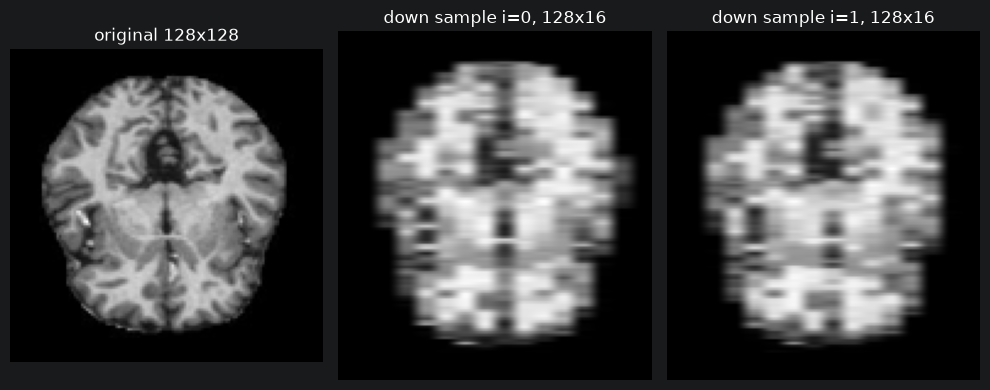

In [21]:
## Show one original image and its first two down sampled versions
f, axes = plt.subplots(1, 3, figsize=(10, 4))
axes[0].imshow(X_train[1].reshape(128, 128), cmap="gray")
axes[0].set_title("original 128x128")
for i in range(2):
    axes[i + 1].imshow(Xds_train[1 * DS + i].reshape(128, 128 // DS), cmap="gray", aspect="auto")
    axes[i + 1].set_title("down sample i=%d, 128x%d" % (i, 128 // DS))
for ax in axes:
    ax.axis("off")
plt.tight_layout()

Now there are more samples (40968) than features (2048), so LDA and linear regression no longer interpolate the training data
exactly. The DS sub-images of one picture are nearly identical, though, so this adds far less information than 8x more real images would.
QDA still needs PCA: the smallest class has 52 × 8 = 416 rows, fewer than the 2048 features. We keep 40 components so it matches Question 2.

In [22]:
models_ds = {
    "LDA": LinearDiscriminantAnalysis(),
    "QDA (on 40 PCA components)": make_pipeline(PCA(n_components=40, random_state=0),
                                                QuadraticDiscriminantAnalysis(reg_param=0.1)),
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Categorical Linear Regression": LinRegClassifier(),
}

In [23]:
preds_ds = {}   ## (train, test) predictions on the down sampled images

In [24]:
## Models already in preds_ds are skipped, as in Question 2
for name, m in models_ds.items():
    if name in preds_ds:
        continue
    t0 = time.time()
    m.fit(Xds_train, yds_train)
    preds_ds[name] = (m.predict(Xds_train), m.predict(Xds_test))
    print("%-30s fit + predict: %.1f s" % (name, time.time() - t0))

LDA                            fit + predict: 13.2 s
QDA (on 40 PCA components)     fit + predict: 2.6 s


/home/wilson/PycharmProjects/WelcomeScreen/MATH7243-ML/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression            fit + predict: 77.6 s
Categorical Linear Regression  fit + predict: 7.2 s


In [25]:
def vote(pred, groups):
    """Majority vote of the DS sub-image predictions for each original image (ties -> lower label)."""
    counts = np.zeros((groups.max() + 1, len(CLASSES)))
    np.add.at(counts, (groups, pred.astype(int)), 1)
    return counts.argmax(axis=1)

## Image-level predictions: one label per original image, comparable to Question 2
img_preds = {name: (vote(p_tr, g_train), vote(p_te, g_test)) for name, (p_tr, p_te) in preds_ds.items()}

results_ds = pd.DataFrame({
    "sub-image train acc": [accuracy_score(yds_train, p[0]) for p in preds_ds.values()],
    "sub-image test acc":  [accuracy_score(yds_test, p[1]) for p in preds_ds.values()],
    "image test acc (vote)":          [accuracy_score(test_y, p[1]) for p in img_preds.values()],
    "image test balanced acc (vote)": [balanced_accuracy_score(test_y, p[1]) for p in img_preds.values()],
}, index=preds_ds.keys())

results_ds.round(3)

,sub-image train acc,sub-image test acc,image test acc (vote),image test balanced acc (vote)
LDA,0.783,0.517,0.540,0.326
QDA (on 40 PCA components),0.642,0.551,0.543,0.392
Logistic Regression,0.778,0.521,0.558,0.323
Categorical Linear Regression,0.769,0.519,0.532,0.296


In [26]:
## Side by side with Question 2 (full resolution, no down sampling)
comparison = pd.DataFrame({
    "Q2 test acc":                results["test acc"].to_numpy(),
    "DS test acc (vote)":         results_ds["image test acc (vote)"].to_numpy(),
    "Q2 test balanced acc":       results["test balanced acc"].to_numpy(),
    "DS test balanced acc (vote)": results_ds["image test balanced acc (vote)"].to_numpy(),
}, index=results_ds.index)

comparison.round(3)

,Q2 test acc,DS test acc (vote),Q2 test balanced acc,DS test balanced acc (vote)
LDA,0.396,0.540,0.290,0.326
QDA (on 40 PCA components),0.535,0.543,0.369,0.392
Logistic Regression,0.598,0.558,0.365,0.323
Categorical Linear Regression,0.561,0.532,0.449,0.296


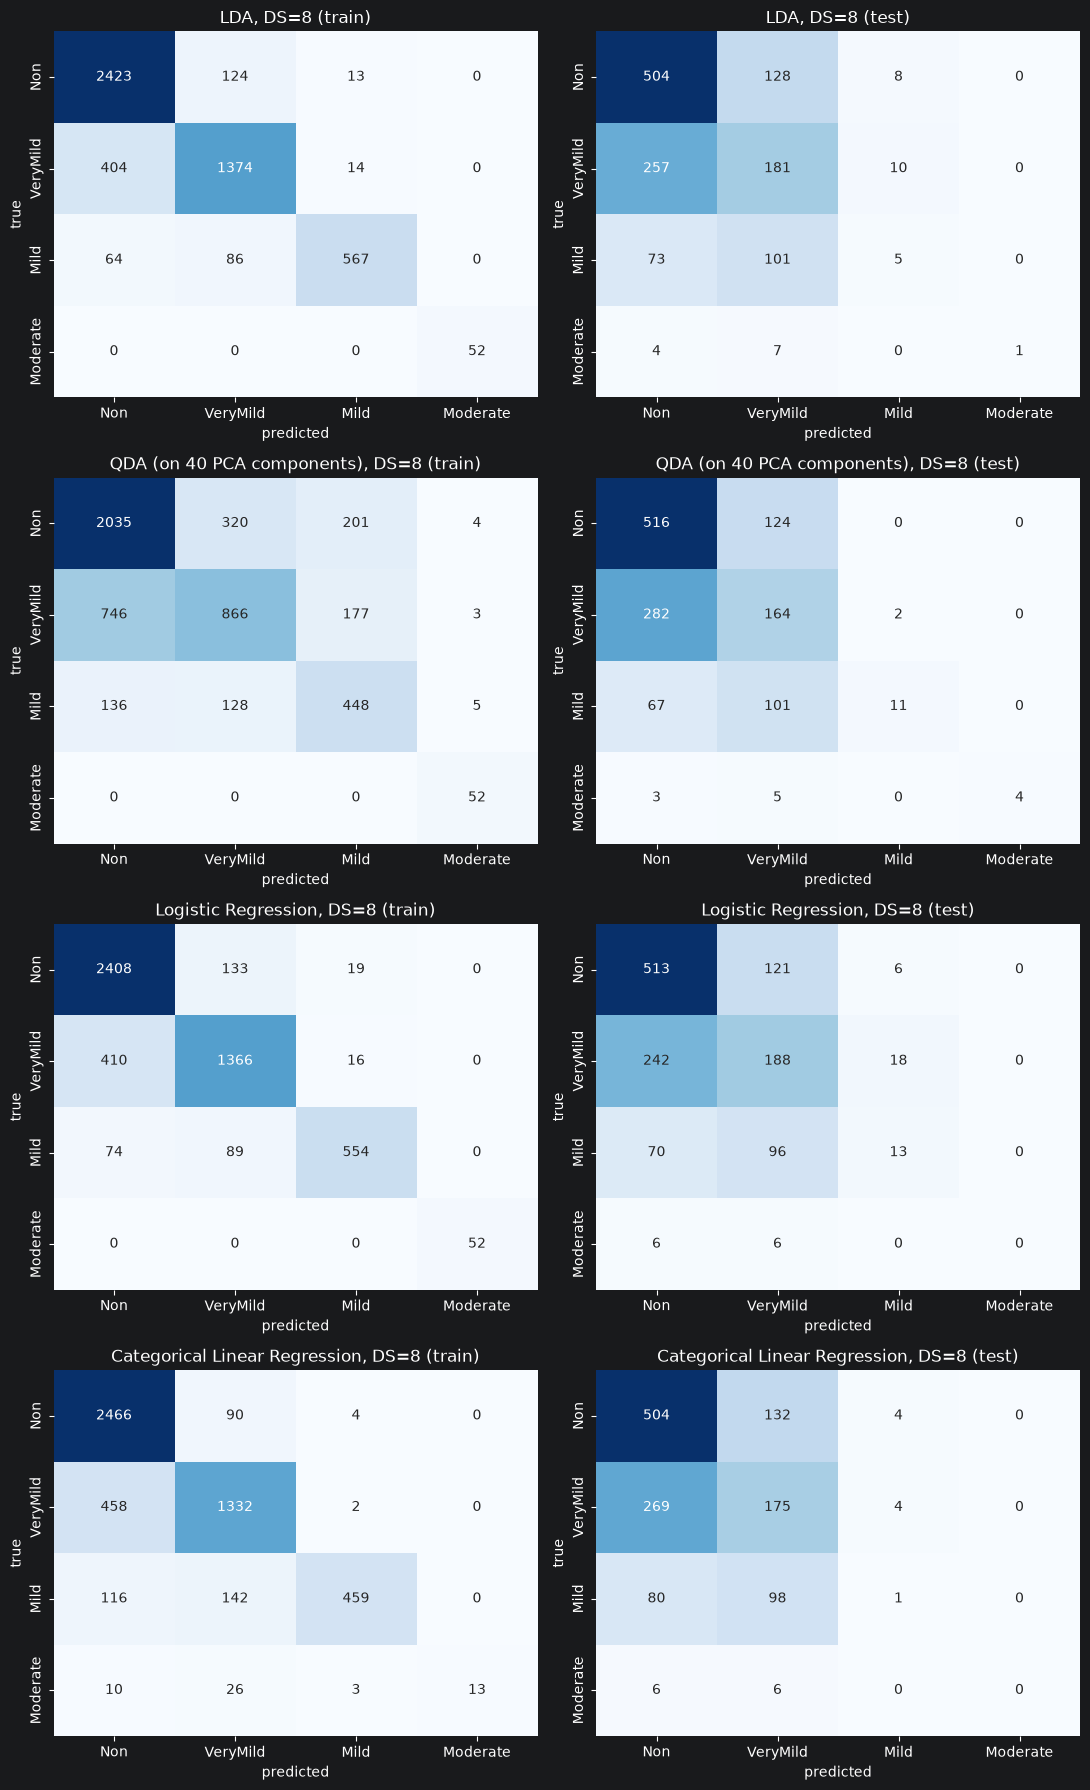

In [27]:
## Confusion matrices on the original images (after voting): rows = true, columns = predicted
f, axes = plt.subplots(len(models_ds), 2, figsize=(11, 18))
for row, (name, (p_train, p_test)) in enumerate(img_preds.items()):
    for col, (y_true, y_pred, split) in enumerate([(train_y, p_train, "train"), (test_y, p_test, "test")]):
        cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=short, yticklabels=short, ax=axes[row, col])
        axes[row, col].set_title("%s, DS=%d (%s)" % (name, DS, split), fontsize=12)
        axes[row, col].set_xlabel("predicted")
        axes[row, col].set_ylabel("true")
plt.tight_layout()

In [28]:
for name, (p_train, p_test) in img_preds.items():
    print(name)
    print("  train:\n", confusion_matrix(train_y, p_train, labels=range(len(CLASSES))))
    print("  test:\n", confusion_matrix(test_y, p_test, labels=range(len(CLASSES))))

LDA
  train:
 [[2423  124   13    0]
 [ 404 1374   14    0]
 [  64   86  567    0]
 [   0    0    0   52]]
  test:
 [[504 128   8   0]
 [257 181  10   0]
 [ 73 101   5   0]
 [  4   7   0   1]]
QDA (on 40 PCA components)
  train:
 [[2035  320  201    4]
 [ 746  866  177    3]
 [ 136  128  448    5]
 [   0    0    0   52]]
  test:
 [[516 124   0   0]
 [282 164   2   0]
 [ 67 101  11   0]
 [  3   5   0   4]]
Logistic Regression
  train:
 [[2408  133   19    0]
 [ 410 1366   16    0]
 [  74   89  554    0]
 [   0    0    0   52]]
  test:
 [[513 121   6   0]
 [242 188  18   0]
 [ 70  96  13   0]
 [  6   6   0   0]]
Categorical Linear Regression
  train:
 [[2466   90    4    0]
 [ 458 1332    2    0]
 [ 116  142  459    0]
 [  10   26    3   13]]
  test:
 [[504 132   4   0]
 [269 175   4   0]
 [ 80  98   1   0]
 [  6   6   0   0]]


### Bonus discussion

**Results with DS = 8** (2048 features per sub-image, 40968 training rows; test accuracy is per original image after the majority vote):

| Model | Q2 test acc | DS test acc | Q2 test balanced | DS test balanced | DS train acc (image) |
|---|---|---|---|---|---|
| LDA | 0.396 | **0.540** | 0.290 | 0.326 | 0.862 |
| QDA (40 PCA) | 0.535 | 0.543 | 0.369 | **0.392** | 0.664 |
| Logistic Regression | **0.598** | 0.558 | 0.365 | 0.323 | 0.855 |
| Categorical Linear Regression | 0.561 | 0.532 | **0.449** | 0.296 | 0.834 |

**Per-class test recall after down sampling:**

| Model | Non | VeryMild | Mild | Moderate |
|---|---|---|---|---|
| LDA | 0.79 | 0.40 | 0.03 | 0.08 |
| QDA | 0.81 | 0.37 | 0.06 | 0.33 |
| Logistic | 0.80 | 0.42 | 0.07 | 0.00 |
| Linear Regression | 0.79 | 0.39 | 0.01 | 0.00 |

**1. Down sampling fixes the p > n problem.** With 40968 rows and 2048 features, no model fits the training set perfectly any more: image-level train accuracy is
66–86% instead of 100%. The sub-image train/test gap shrinks from 40–60 points in Question 2 to about 25 points (LDA, logistic and linear regression) and
9 points (QDA). LDA benefits most. In Question 2 its singular pooled covariance made it predict ModerateDemented for 307 test images, and it fell below the
50% baseline. Now its covariance can be estimated, and its test accuracy rises from 39.6% to 54.0%.

**2. But generalization does not improve overall.** All four models now end up at 53–56% test accuracy, only a few points above always guessing
NonDemented (50%). The best model gets worse: logistic regression drops from 59.8% to 55.8%. Balanced accuracy falls for logistic regression and sharply for
linear regression (0.449 → 0.296). The models now almost never recognize MildDemented (at most 7% recall, vs. up to 26% before) and predict nearly
everything as NonDemented or VeryMildDemented. The problem has moved from overfitting (variance) to lost information (bias).

**3. Why.** The 8 sub-images of one MRI are nearly identical horizontally shifted copies, so the dataset is not really 8× larger: it still holds
information from only 5121 distinct images, and from only 52 ModerateDemented ones. What changes is that each sub-image keeps only every 8th column
(128 × 16 pixels), throwing away most of the horizontal detail that separates neighbouring dementia stages. The fewer features act as regularization,
which helps the unstable LDA, but they also remove the signal the better models were using. The training confusion matrices show the copies are still
memorized for the rare class: LDA, QDA and logistic regression classify all 52 ModerateDemented training images correctly, yet get 0–4 of the 12 test images right.

**4. Majority voting helps a little.** Combining the 8 sub-image predictions per image raises test accuracy by 1–4 points for LDA, logistic and
linear regression (e.g. logistic 52.1% → 55.8%), and slightly lowers it for QDA (55.1% → 54.3%). Errors on the 8 copies are strongly correlated, so voting
can't fix much.

**5. Caveat.** Logistic regression hit `max_iter=500` without converging, so its numbers could change slightly with more iterations. Both results come
from a single train/test split.

**Conclusion.** Down sampling with DS = 8 makes every method numerically well posed and removes the extreme overfitting from Question 2, which matters most
for LDA. It does not make the models better at recognizing dementia: the "new" images carry no new information, and keeping every 8th column discards useful
detail. Better options would be to down sample in both directions (e.g. average 2×2 or 4×4 pixel blocks, keeping the image shape), try a smaller DS, use PCA,
or regularize with `class_weight="balanced"` so the rare dementia classes are not ignored.